# Optimizer benchmark: Nuevolution vs. CMA-ES

DidgeLab has two optimizers for bore shapes:

* **`Nuevolution`**: a genetic algorithm. It keeps a population of genomes and creates offspring with
  mutation (random noise on the genes) and crossover (mixing the genes of two parents).
* **`CMAES`**: the covariance matrix adaptation evolution strategy. It samples each generation from a
  multivariate normal distribution and adapts the mean, the step size and the covariance of that distribution
  from the best samples. It learns which genes have to change *together* (e.g. bore length and bell
  diameter for a given drone) and controls its own mutation strength.

This notebook runs both on several **shapes** (genome types) and **targets** (loss functions) and compares
them at the **same number of loss evaluations**. The loss evaluation (one acoustical simulation) dominates
the run time, so equal evaluations means roughly equal compute.

Contents:

1. Setup and benchmark parameters
2. Shapes
3. Targets
4. Optimizers and how the budget is counted
5. Running the benchmark
6. Results: final loss, convergence curves, evaluations needed
7. Example: the best bores of both optimizers
8. Conclusions

## 1. Setup

`BUDGET` is the number of loss evaluations per run, `SEEDS` the random seeds per scenario. With the defaults
the benchmark takes a few minutes on a laptop. Increase both for tighter results.

In [1]:
import sys
sys.path.insert(0, "../../src")

import logging
import threading
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from didgelab import (
    CMAES,
    CompositeTairuaLoss,
    FrequencyTuningLoss,
    GeoGenomeA,
    HarmonicSplittingLoss,
    HighInharmonicLoss,
    IntegerHarmonicLoss,
    KigaliShape,
    ModalDensityLoss,
    NearIntegerLoss,
    Nuevolution,
    PeakAmplitudeLoss,
    PeakQuantityLoss,
    QFactorLoss,
    ScaleTuningLoss,
    StretchedOddLoss,
)
from didgelab.acoustical_simulation import acoustical_simulation, get_log_simulation_frequencies
from didgelab.app import init_app
from didgelab.shapes.MbeyaShape import MbeyaGenome

init_app("optimizer_benchmark", create_output_folder=False)
logging.disable(logging.WARNING)

BUDGET = 3000        # loss evaluations per run
SEEDS = [1, 2, 3]    # random seeds per scenario

## 2. Shapes

Four genome types with different numbers of genes and different relations between genes and geometry:

| Shape | Genes | Description |
|-------|-------|-------------|
| `KigaliShape()` | 49 | Power-law taper with per-segment jitter (the default shape of the web app). |
| `KigaliShape(n_bubbles=2)` | 55 | Same plus two bulges, each with position, width and height. |
| `MbeyaGenome(n_bubbles=2)` | 17 | Named parameters: straight tube, opening section, bell, bubbles. |
| `GeoGenomeA.build(8)` | 17 | Eight segments, each with a free relative length and diameter. |

In [2]:
SHAPES = {
    "Kigali": lambda: KigaliShape(),
    "Kigali + bubbles": lambda: KigaliShape(n_bubbles=2),
    "Mbeya": lambda: MbeyaGenome(n_bubbles=2),
    "GeoGenomeA": lambda: GeoGenomeA.build(8),
}
for name, make in SHAPES.items():
    print(f"{name:18s} {len(make().genome):3d} genes")

Kigali              49 genes
Kigali + bubbles    55 genes
Mbeya               17 genes
GeoGenomeA          17 genes


## 3. Targets

Four loss functions, from a single target to the full set of loss components:

* **Drone D2**: one target, the drone at D2 (73.4 Hz).
* **Drone + toots**: drone D2 and three toots (F#3, D4, G4), drone weighted twice.
* **Scale**: drone + toots plus all resonances pulled towards D minor pentatonic and at least six peaks.
* **Full composite**: all eleven loss components (tuning, scale, peak count and height, Q factor, modal
  density, harmonic series, ...), the same set as in
  [loss/12_full_example.ipynb](loss/12_full_example.ipynb) and the unit tests.

Loss values are only comparable within one target, not across targets.

In [3]:
TOOTS_HZ = np.array([73.4, 185.0, 293.7, 392.0])  # D2, F#3, D4, G4


def drone_loss():
    loss = CompositeTairuaLoss()
    loss.add_component("freq", FrequencyTuningLoss(np.log2([73.4]), np.array([-1.0]), [1.0]))
    loss.target_freqs = np.array([73.4])
    return loss


def toots_loss():
    loss = CompositeTairuaLoss()
    loss.add_component("freq", FrequencyTuningLoss(np.log2(TOOTS_HZ), np.full(4, -1.0), [2.0, 1.0, 1.0, 0.5]))
    loss.target_freqs = TOOTS_HZ
    return loss


def scale_loss():
    loss = toots_loss()
    loss.add_component("scale", ScaleTuningLoss(62, [0, 3, 5, 7, 10], weight=2.0))  # D minor pentatonic
    loss.add_component("peaks_qty", PeakQuantityLoss(target_count=6, weight=1.0))
    return loss


def full_loss():
    targets = np.array([73.4, 146.8])
    loss = CompositeTairuaLoss()
    loss.add_component("freq", FrequencyTuningLoss(np.log2(targets), np.full(2, -1.0), [1.0, 1.0]))
    loss.add_component("scale", ScaleTuningLoss(60, [0, 2, 4, 5, 7, 9, 11], weight=5.0))
    loss.add_component("peaks_qty", PeakQuantityLoss(target_count=4, weight=2.0))
    loss.add_component("peaks_amp", PeakAmplitudeLoss(target_min_amplitude=0.25, weight=10.0))
    loss.add_component("q_factor", QFactorLoss(target_q=15.0, weight=1.0))
    loss.add_component("modal_density", ModalDensityLoss(cluster_range_cents=50.0, weight=1.0))
    loss.add_component("integer_harmonic", IntegerHarmonicLoss(weight=1.0))
    loss.add_component("near_integer", NearIntegerLoss(stretch_factor=1.002, weight=1.0))
    loss.add_component("stretched_odd", StretchedOddLoss(weight=1.0))
    loss.add_component("high_inharmonic", HighInharmonicLoss(weight=1.0))
    loss.add_component("harmonic_splitting", HarmonicSplittingLoss(harmonic_index=1, split_width_hz=5.0, weight=1.0))
    loss.target_freqs = targets
    return loss


TARGETS = {
    "Drone D2": drone_loss,
    "Drone + toots": toots_loss,
    "Scale": scale_loss,
    "Full composite": full_loss,
}

## 4. Optimizers and budget

Three optimizer configurations:

* **Nuevolution 16/20**: generation size 16, population 20, all six default operators, fixed mutation rate.
* **Nuevolution 50/400**: generation size 50, population 400, the defaults of the web app's evolution runner.
* **CMA-ES**: 16 samples per generation, initial step size 0.3 in genome units, mean starting at the centre of
  the genome box.

The loss is wrapped in `Tracked`, which counts every *fresh* loss evaluation (cached losses on already
evaluated genomes are free and not counted) and records the best total loss seen so far after each one.
Each optimizer gets as many generations as fit into `BUDGET`.

In [4]:
class Tracked:
    # Loss wrapper: counts fresh evaluations, records the running best total loss.

    def __init__(self, loss):
        self.inner = loss
        self.lock = threading.Lock()
        self.best = np.inf
        self.curve = []

    def loss(self, shape):
        if getattr(shape, "loss", None) is not None:
            return shape.loss
        result = self.inner.loss(shape)
        with self.lock:
            self.best = min(self.best, result["total"])
            self.curve.append(self.best)
        return result


def silent(*args):
    pass


def nuevolution(generation_size, population_size):
    def run(loss, father, budget):
        evo = Nuevolution(
            loss, father,
            generation_size=generation_size,
            population_size=population_size,
            num_generations=budget // generation_size - 1,
            callback_loss_progress=silent,
        )
        return evo.evolve()
    return run


def cmaes(loss, father, budget):
    return CMAES(loss, father, num_generations=budget // 16, population_size=16, sigma0=0.3).evolve()


OPTIMIZERS = {
    "Nuevolution 16/20": nuevolution(16, 20),
    "Nuevolution 50/400": nuevolution(50, 400),
    "CMA-ES": cmaes,
}

## 5. Running the benchmark

Every combination of shape, target, optimizer and seed is one run. Each optimizer sees the same seeds.

In [5]:
runs = []
start = time.time()
for target_name, make_loss in TARGETS.items():
    for shape_name, make_shape in SHAPES.items():
        for optimizer_name, optimize in OPTIMIZERS.items():
            for seed in SEEDS:
                np.random.seed(seed)
                loss = Tracked(make_loss())
                t = time.time()
                population = optimize(loss, make_shape(), BUDGET)
                runs.append({
                    "target": target_name,
                    "shape": shape_name,
                    "optimizer": optimizer_name,
                    "seed": seed,
                    "final_loss": population[0].loss["total"],
                    "evaluations": len(loss.curve),
                    "seconds": time.time() - t,
                    "curve": np.array(loss.curve),
                    "best": population[0],
                })
        print(f"{target_name:15s} {shape_name:17s} done after {time.time() - start:5.0f} s")

results = pd.DataFrame(runs)
print(f"{len(results)} runs, {results["evaluations"].sum():,} loss evaluations")

Drone D2        Kigali            done after    54 s


Drone D2        Kigali + bubbles  done after   120 s


Drone D2        Mbeya             done after   187 s


Drone D2        GeoGenomeA        done after   224 s


Drone + toots   Kigali            done after   305 s


Drone + toots   Kigali + bubbles  done after   393 s


... (6 outputs left out)

Full composite  Kigali            done after   939 s


Full composite  Kigali + bubbles  done after  1006 s


Full composite  Mbeya             done after  1077 s


Full composite  GeoGenomeA        done after  1130 s
144 runs, 431,232 loss evaluations


## 6. Results

### 6.1 Final loss

Mean best loss per scenario after `BUDGET` evaluations (lower is better), and the CMA-ES loss relative to
the better of the two Nuevolution configurations. A ratio below 1 means CMA-ES found better bores.

In [6]:
table = results.pivot_table(index=["target", "shape"], columns="optimizer", values="final_loss", aggfunc="mean")
table = table.loc[list(TARGETS)]
best_ga = table[["Nuevolution 16/20", "Nuevolution 50/400"]].min(axis=1)
table["CMA-ES / best GA"] = table["CMA-ES"] / best_ga
table.style.format("{:.3f}").background_gradient(subset=["CMA-ES / best GA"], cmap="RdYlGn_r", vmin=0.5, vmax=1.5)

How often each optimizer had the best final loss of the three, over all scenarios and seeds (one win per
shape, target and seed):

In [7]:
per_seed = results.pivot_table(index=["target", "shape", "seed"], columns="optimizer", values="final_loss")
wins = per_seed.idxmin(axis=1).value_counts().reindex(list(OPTIMIZERS), fill_value=0)
print(wins.to_string())
print(f"\nmean wall-clock seconds per run:")
print(results.groupby("optimizer")["seconds"].mean().round(1).to_string())

Nuevolution 16/20      9
Nuevolution 50/400     6
CMA-ES                33

mean wall-clock seconds per run:


optimizer
CMA-ES                 3.5
Nuevolution 16/20      4.6
Nuevolution 50/400    15.5


### 6.2 Convergence curves

Best loss found so far against the number of loss evaluations, median over the seeds (line) and the range
over the seeds (band). One panel per scenario: rows are targets, columns are shapes.

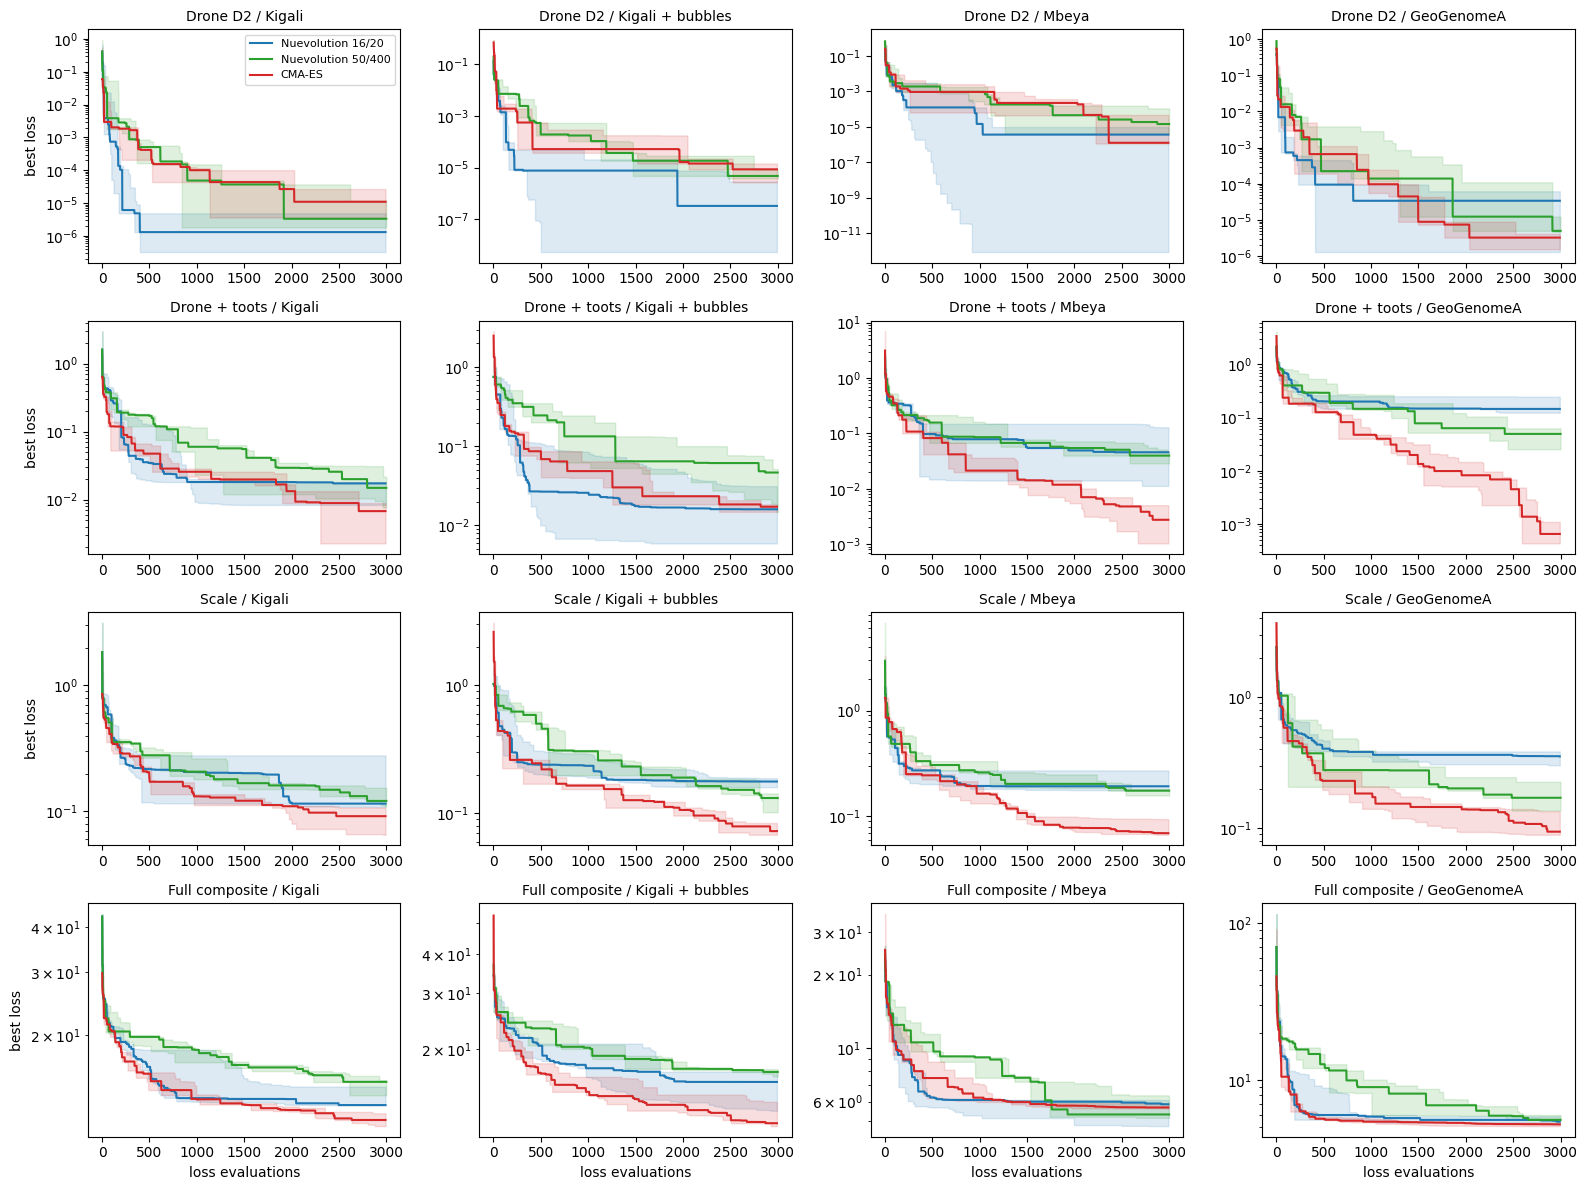

In [8]:
colors = {"Nuevolution 16/20": "tab:blue", "Nuevolution 50/400": "tab:green", "CMA-ES": "tab:red"}
fig, axes = plt.subplots(len(TARGETS), len(SHAPES), figsize=(4 * len(SHAPES), 3 * len(TARGETS)), squeeze=False)
for i, target_name in enumerate(TARGETS):
    for j, shape_name in enumerate(SHAPES):
        ax = axes[i, j]
        for optimizer_name in OPTIMIZERS:
            sel = results[(results["target"] == target_name) & (results["shape"] == shape_name)
                          & (results["optimizer"] == optimizer_name)]
            n = min(len(c) for c in sel["curve"])
            curves = np.vstack([c[:n] for c in sel["curve"]])
            x = np.arange(1, n + 1)
            ax.plot(x, np.median(curves, axis=0), color=colors[optimizer_name], label=optimizer_name)
            ax.fill_between(x, curves.min(axis=0), curves.max(axis=0), color=colors[optimizer_name], alpha=0.15)
        ax.set_yscale("log")
        ax.set_title(f"{target_name} / {shape_name}", fontsize=10)
        if i == len(TARGETS) - 1:
            ax.set_xlabel("loss evaluations")
        if j == 0:
            ax.set_ylabel("best loss")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 6.3 Evaluations needed

How many evaluations CMA-ES needs (median curve) to reach the final loss that the better Nuevolution
configuration reaches with the full `BUDGET`. A value of 750 with a budget of 3000 means CMA-ES is 4x more
efficient in that scenario. "-" means CMA-ES does not reach it within the budget.

In [9]:
rows = []
for (target_name, shape_name), sel in results.groupby(["target", "shape"], sort=False):
    def median_curve(name):
        curves = [c for c in sel[sel["optimizer"] == name]["curve"]]
        n = min(len(c) for c in curves)
        return np.median(np.vstack([c[:n] for c in curves]), axis=0)
    ga_final = min(median_curve("Nuevolution 16/20")[-1], median_curve("Nuevolution 50/400")[-1])
    reached = np.nonzero(median_curve("CMA-ES") <= ga_final)[0]
    evals = reached[0] + 1 if len(reached) else None
    rows.append({"target": target_name, "shape": shape_name, "best GA final": ga_final,
                 "CMA-ES evaluations to match": evals,
                 "speed-up": BUDGET / evals if evals else None})
speedup = pd.DataFrame(rows).set_index(["target", "shape"])
speedup.style.format({"best GA final": "{:.3f}", "CMA-ES evaluations to match": "{:.0f}", "speed-up": "{:.1f}x"},
                     na_rep="-")

## 7. Example: the best bores

The best bore of each optimizer (over all seeds) for *Drone + toots* on the Kigali shape, with its impedance
spectrum. The dashed lines are the target frequencies.

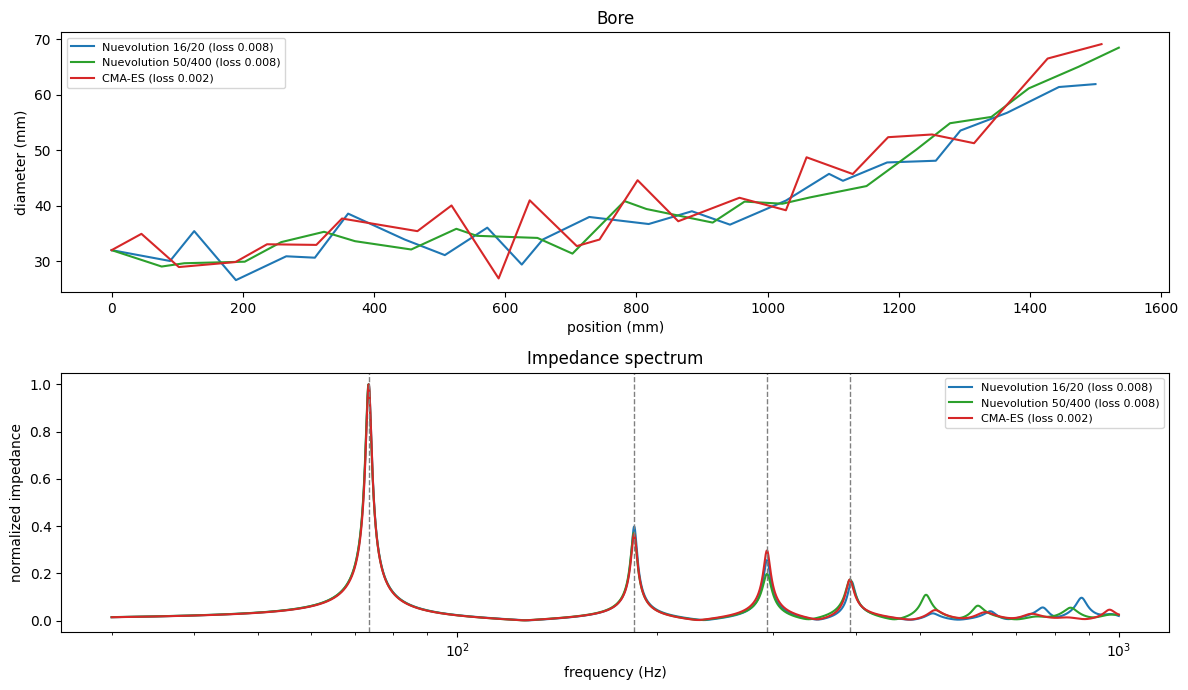

In [10]:
target_name, shape_name = "Drone + toots", "Kigali"
freqs = get_log_simulation_frequencies(30, 1000, 2)
fig, (ax_bore, ax_imp) = plt.subplots(2, 1, figsize=(12, 7))
for optimizer_name in OPTIMIZERS:
    sel = results[(results["target"] == target_name) & (results["shape"] == shape_name)
                  & (results["optimizer"] == optimizer_name)]
    run = sel.loc[sel["final_loss"].idxmin()]
    geo = run["best"].genome2geo()
    label = f"{optimizer_name} (loss {run["final_loss"]:.3f})"
    x, d = np.array(geo.geo).T
    ax_bore.plot(x, d, color=colors[optimizer_name], label=label)
    impedance = np.asarray(acoustical_simulation(geo, freqs))
    ax_imp.plot(freqs, impedance / impedance.max(), color=colors[optimizer_name], label=label)
for f in TOOTS_HZ:
    ax_imp.axvline(f, color="gray", linestyle="--", linewidth=1)
ax_bore.set_xlabel("position (mm)")
ax_bore.set_ylabel("diameter (mm)")
ax_bore.set_title("Bore")
ax_bore.legend(fontsize=8)
ax_imp.set_xscale("log")
ax_imp.set_xlabel("frequency (Hz)")
ax_imp.set_ylabel("normalized impedance")
ax_imp.set_title("Impedance spectrum")
ax_imp.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 8. Conclusions

Results of the run above (budget 3000 evaluations, 3 seeds, 16 scenarios):

* **CMA-ES is the better optimizer for real tuning tasks.** It had the best final loss in 33 of 48
  scenario/seed combinations (Nuevolution 16/20: 9, Nuevolution 50/400: 6). On *Scale* it ends 1.5-2.2x lower
  than the better GA configuration on every shape, on *Drone + toots* 2.4-60x lower (except one shape, see
  below), on *Full composite* 6-19% lower on three of four shapes. Where it matches the GA's final loss, it
  needs 650-1950 of the 3000 evaluations (section 6.3): roughly 1.5-4.5x fewer simulations for the same
  result.
* **The gap grows with the number of coupled targets.** One drone is easy for every optimizer: all three
  reach a loss below $10^{-4}$, i.e. well under 0.1 cent, so the differences in the *Drone D2* row (and its
  ratios in table 6.1) are numerical noise, not musical differences. Hitting four peaks at once, or a whole
  scale, needs several genes to change together (length, taper and bell together move all peaks). CMA-ES
  learns these correlations in its covariance matrix; mutation and crossover only find them by chance.
* **It helps most on compact genomes.** On `GeoGenomeA` and `Mbeya` (17 genes) CMA-ES reaches 60x and 13x lower
  losses on *Drone + toots*. On the 49-55-gene Kigali shapes the advantage is smaller but consistent for
  *Scale* and *Full composite*.
* **Exceptions:** on *Full composite / Mbeya* all three end at about the same loss (CMA-ES ratio 1.03), and on
  *Drone + toots / Kigali + bubbles* Nuevolution 16/20 is on par. Within the first few hundred evaluations
  the small GA is sometimes ahead (it exploits its best individuals greedily), CMA-ES overtakes it later.
* **CMA-ES is more reliable.** The bands in 6.2 (range over seeds) are narrower for CMA-ES on most panels:
  the result depends less on luck.
* **The web app's configuration (50/400) is the weakest.** With 3000 evaluations it only runs 60
  generations, and keeping a population of 400 costs extra time per generation (15.5 s per run vs. 3.5 s for
  CMA-ES at the same number of simulations).

Recommendation: use `CMAES` for shape optimization, with a population size of about 16 and `sigma0=0.3` when
starting from scratch. To refine an existing bore, start from it with `start_from_father=True` and a small
`sigma0` (e.g. 0.05).